# Correção — Exercício Aula 07
## Fundamentos de Mineração de Dados + Coleta de Dados (REST/MongoDB)

**Curso:** Ciência de Dados | **Instituição:** Univassouras
**Prof. Mesc. Diego Ramos Inácio**

---

Este exercício usa **cenários diferentes** dos vistos na aula (lojas de streaming, academia, lanchonete, API de posts), mas aplica exatamente os mesmos conceitos de [Aula_07_Mineracao_Dados.ipynb](Aula_07_Mineracao_Dados.ipynb). Se um termo ou sigla não estiver claro aqui, a explicação completa está naquele notebook.

| Parte | Tema | Exercícios |
|-------|------|------------|
| 1 | Mineração de Dados | Ex. 1 a 4 |
| 2 | Coleta de Dados (REST + MongoDB) | Ex. 5 |

> Execute cada célula com **Shift+Enter** de cima para baixo.

> **Bibliotecas necessárias:** `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`, `requests`, `pymongo`
> Instale com: `pip install numpy pandas matplotlib seaborn scikit-learn requests pymongo`
> O Exercício 5 exige um servidor **MongoDB** acessível em `mongodb://localhost:27017`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report

plt.rcParams['figure.dpi'] = 100
sns.set_theme(style='whitegrid', palette='tab10')

np.random.seed(42)
print('Ambiente pronto!')

Ambiente pronto!


---
# PARTE 1 — Mineração de Dados

## Exercício 1 — Pré-processamento

Uma escola recebeu os dados de inscrição de um curso, mas o arquivo está sujo: tem aluno duplicado, **idade** e **nota de entrada** ausentes (faltando), e uma coluna categórica (`nivel_ingles`) que precisa virar número antes de qualquer modelo.

Limpe o dataset abaixo: remova duplicatas, preencha os valores ausentes com a mediana e codifique as colunas categóricas (`nivel_ingles` e `aprovado`).

In [2]:
dados_brutos = pd.DataFrame({
    'aluno_id':      [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 10],  # 10 duplicado!
    'idade':         [19, None, 22, 25, 20, 30, None, 24, 21, 28, 28],
    'nota_entrada':  [7.5, 6.0, None, 8.2, 7.0, 9.1, 6.5, None, 7.8, 8.9, 8.9],
    'nivel_ingles':  ['basico', 'intermediario', 'avancado', 'avancado', 'basico',
                      'avancado', 'basico', 'intermediario', 'intermediario', 'avancado', 'avancado'],
    'aprovado':      ['sim', 'não', 'sim', 'sim', 'não', 'sim', 'não', 'sim', 'sim', 'sim', 'sim']
})

print('=== Dataset original (com problemas) ===')
print(f'\nFormato: {dados_brutos.shape[0]} linhas x {dados_brutos.shape[1]} colunas')
print(f'\nValores ausentes por coluna:')
print(dados_brutos.isnull().sum())

dados_brutos

=== Dataset original (com problemas) ===

Formato: 11 linhas x 5 colunas

Valores ausentes por coluna:
aluno_id        0
idade           2
nota_entrada    2
nivel_ingles    0
aprovado        0
dtype: int64


,aluno_id,idade,nota_entrada,nivel_ingles,aprovado
0,1,19.0,7.5,basico,sim
1,2,NaN,6.0,intermediario,não
2,3,22.0,NaN,avancado,sim
3,4,25.0,8.2,avancado,sim
4,5,20.0,7.0,basico,não
5,6,30.0,9.1,avancado,sim
6,7,NaN,6.5,basico,não
7,8,24.0,NaN,intermediario,sim
8,9,21.0,7.8,intermediario,sim
9,10,28.0,8.9,avancado,sim


In [3]:
# 1. Remover duplicatas (mesmo aluno_id repetido)
df_escola = dados_brutos.drop_duplicates(subset='aluno_id')
print(f'Após remover duplicatas: {len(df_escola)} linhas')

# 2. Preencher valores ausentes com a mediana (mais robusta a outliers que a média)
df_escola['idade'] = df_escola['idade'].fillna(df_escola['idade'].median())
df_escola['nota_entrada'] = df_escola['nota_entrada'].fillna(df_escola['nota_entrada'].median())
print(f'Valores ausentes restantes: {df_escola.isnull().sum().sum()}')

# 3. Codificar variáveis categóricas (LabelEncoder transforma categorias em números: 0, 1, 2...)
le_nivel = LabelEncoder()
le_aprovado = LabelEncoder()

df_escola['nivel_ingles_cod'] = le_nivel.fit_transform(df_escola['nivel_ingles'])
df_escola['aprovado_cod'] = le_aprovado.fit_transform(df_escola['aprovado'])

print('\nCodificação de "nivel_ingles":', dict(zip(le_nivel.classes_, le_nivel.transform(le_nivel.classes_))))
print('Codificação de "aprovado":', dict(zip(le_aprovado.classes_, le_aprovado.transform(le_aprovado.classes_))))

print('\n=== Dataset limpo e codificado ===')
print(df_escola[['aluno_id', 'idade', 'nota_entrada', 'nivel_ingles', 'nivel_ingles_cod',
                  'aprovado', 'aprovado_cod']])

Após remover duplicatas: 10 linhas
Valores ausentes restantes: 0

Codificação de "nivel_ingles": {'avancado': np.int64(0), 'basico': np.int64(1), 'intermediario': np.int64(2)}
Codificação de "aprovado": {'não': np.int64(0), 'sim': np.int64(1)}

=== Dataset limpo e codificado ===
   aluno_id  idade  nota_entrada   nivel_ingles  nivel_ingles_cod aprovado  \
0         1   19.0          7.50         basico                 1      sim   
1         2   23.0          6.00  intermediario                 2      não   
2         3   22.0          7.65       avancado                 0      sim   
3         4   25.0          8.20       avancado                 0      sim   
4         5   20.0          7.00         basico                 1      não   
5         6   30.0          9.10       avancado                 0      sim   
6         7   23.0          6.50         basico                 1      não   
7         8   24.0          7.65  intermediario                 2      sim   
8         9   21.0

## Exercício 2 — Classificação com Árvore de Decisão

Uma empresa de streaming quer prever se um assinante vai **cancelar o plano** (*churn*, "evasão de clientes") com base em duas features (variáveis de entrada): o **tempo de uso** (em meses) e o **número de reclamações** abertas.

Separe features (X) e alvo (y), treine uma Árvore de Decisão e avalie com `classification_report` (as mesmas métricas vistas na Aula 07: *precision*, *recall*, *f1-score* e *support*).

In [4]:
n = 200
meses_uso = np.random.randint(1, 36, n)
reclamacoes = np.random.randint(0, 10, n)

# regra artificial: poucos meses de uso + muitas reclamações → tende a cancelar
cancelou = ((reclamacoes > 3) & (meses_uso < 12)).astype(int)

# ruído: 15% de chance de inverter o resultado, simulando exceções do mundo real
ruido = np.random.choice([0, 1], n, p=[0.85, 0.15])
cancelou = np.abs(cancelou - ruido).clip(0, 1)

df_churn = pd.DataFrame({'meses_uso': meses_uso, 'reclamacoes': reclamacoes, 'cancelou': cancelou})
print(f'Dataset de classificação: {len(df_churn)} registros')
print(f'Distribuição do alvo: {df_churn["cancelou"].value_counts().to_dict()}  (0=ficou, 1=cancelou)')

Dataset de classificação: 200 registros
Distribuição do alvo: {0: 136, 1: 64}  (0=ficou, 1=cancelou)


Treino: 160 amostras | Teste: 40 amostras

Acurácia no conjunto de teste: 75.00%

Relatório detalhado:
              precision    recall  f1-score   support

       Ficou       0.75      0.92      0.83        26
    Cancelou       0.75      0.43      0.55        14

    accuracy                           0.75        40
   macro avg       0.75      0.68      0.69        40
weighted avg       0.75      0.75      0.73        40



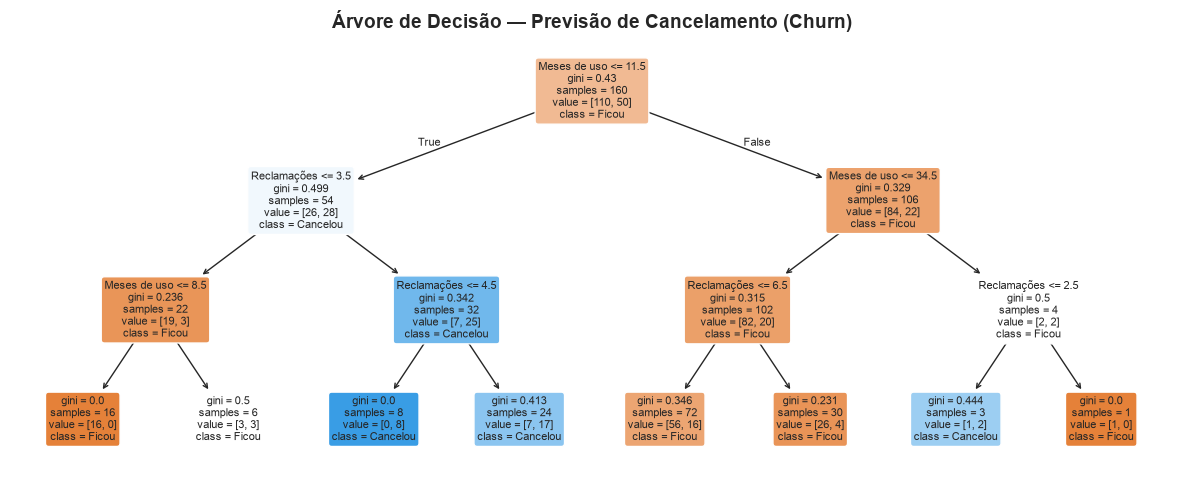

In [5]:
# ── Separar X (features) e y (alvo) ────────────────────────────────────────
X = df_churn[['meses_uso', 'reclamacoes']]
y = df_churn['cancelou']

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Treino: {len(X_treino)} amostras | Teste: {len(X_teste)} amostras')

# ── Treinar e avaliar a Árvore de Decisão ──────────────────────────────────
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(X_treino, y_treino)

y_pred = modelo.predict(X_teste)
acc = accuracy_score(y_teste, y_pred)

print(f'\nAcurácia no conjunto de teste: {acc:.2%}')
print('\nRelatório detalhado:')
print(classification_report(y_teste, y_pred, target_names=['Ficou', 'Cancelou']))

# ── Visualizar a árvore ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))
plot_tree(modelo, feature_names=['Meses de uso', 'Reclamações'], class_names=['Ficou', 'Cancelou'],
          filled=True, rounded=True, ax=ax)
ax.set_title('Árvore de Decisão — Previsão de Cancelamento (Churn)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Exercício 3 — Agrupamento com K-Means

Uma rede de academias quer segmentar seus alunos por **frequência semanal de treino** e **tempo médio de permanência na academia** (em minutos), para montar planos personalizados.

Use o Método do Cotovelo para escolher o número de clusters (K) e depois segmente os alunos.

In [6]:
# 3 perfis de aluno bem definidos
g1 = np.random.multivariate_normal([1, 25], [[0.3, 0], [0, 20]], 60)   # pouco frequente, visita curta
g2 = np.random.multivariate_normal([3, 50], [[0.5, 0], [0, 40]], 60)   # frequência média, tempo médio
g3 = np.random.multivariate_normal([5, 80], [[0.5, 0], [0, 60]], 60)   # muito frequente, visita longa

dados_academia = pd.DataFrame(
    np.vstack([g1, g2, g3]),
    columns=['frequencia_semanal', 'tempo_medio_min']
).clip(lower=0)

print(f'Dataset de academia: {len(dados_academia)} alunos')
dados_academia.describe().round(1)

Dataset de academia: 180 alunos


,frequencia_semanal,tempo_medio_min
count,180.0,180.0
mean,3.0,51.2
std,1.8,23.0
min,0.0,15.8
25%,1.4,27.5
50%,2.9,51.6
75%,4.5,74.4
max,6.9,99.8


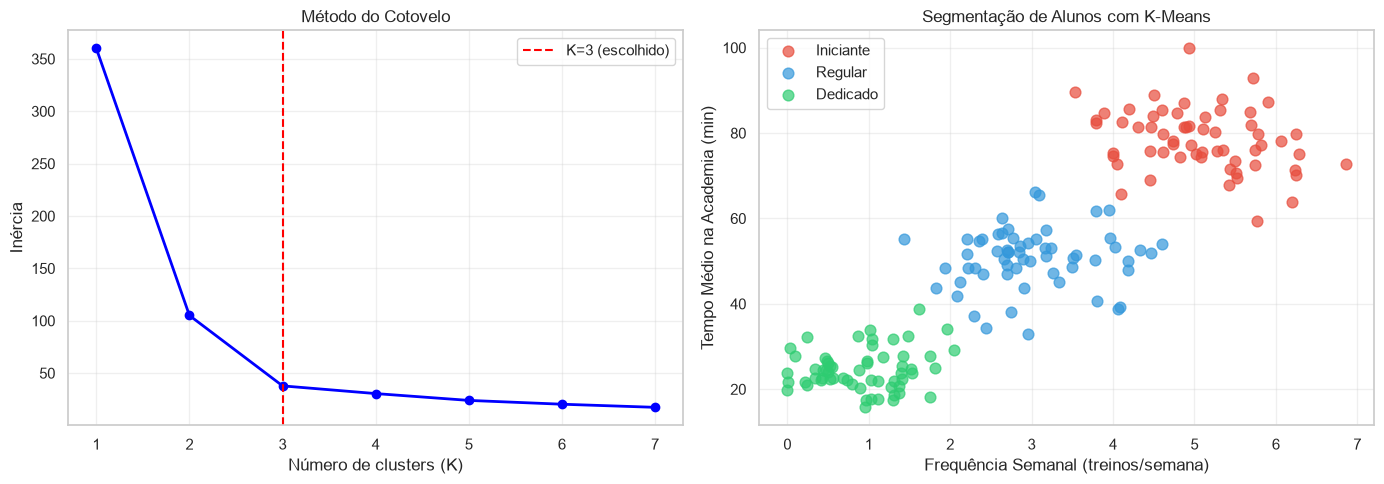

Distribuição por segmento:
segmento
Dedicado     60
Regular      60
Iniciante    60
Name: count, dtype: int64


In [7]:
# ── Escalar antes do K-Means (necessário: frequência vai de 0-7, tempo de 0-100+) ──
scaler = StandardScaler()
X_scaled = scaler.fit_transform(dados_academia)

# ── Método do cotovelo para escolher K ─────────────────────────────────────
# Inércia = soma das distâncias ao quadrado de cada ponto até o centro do seu grupo;
# quanto mais clusters, menor a inércia, mas o ganho desacelera — o "cotovelo" da curva
# é o K escolhido.
inercias = []
ks = range(1, 8)
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inercias.append(km.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(ks, inercias, 'bo-', linewidth=2)
axes[0].axvline(x=3, color='red', linestyle='--', label='K=3 (escolhido)')
axes[0].set_xlabel('Número de clusters (K)')
axes[0].set_ylabel('Inércia')
axes[0].set_title('Método do Cotovelo')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ── Clusterização final com K=3 ─────────────────────────────────────────────
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
dados_academia['segmento'] = kmeans.fit_predict(X_scaled)

cores = {0: '#e74c3c', 1: '#3498db', 2: '#2ecc71'}
rotulos = {0: 'Iniciante', 1: 'Regular', 2: 'Dedicado'}

for seg in [0, 1, 2]:
    mask = dados_academia['segmento'] == seg
    axes[1].scatter(dados_academia.loc[mask, 'frequencia_semanal'],
                    dados_academia.loc[mask, 'tempo_medio_min'],
                    c=cores[seg], label=rotulos[seg], alpha=0.7, s=60)

axes[1].set_xlabel('Frequência Semanal (treinos/semana)')
axes[1].set_ylabel('Tempo Médio na Academia (min)')
axes[1].set_title('Segmentação de Alunos com K-Means')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print('Distribuição por segmento:')
print(dados_academia['segmento'].value_counts().rename(rotulos))

## Exercício 4 — Regras de Associação

Uma lanchonete quer saber quais itens do cardápio costumam ser pedidos juntos, para montar combos. A partir das transações abaixo, calcule **suporte**, **confiança** e **lift** para os pares de itens mais frequentes.

> Lembrete rápido (visto em detalhe na Aula 07): **N** = total de transações; **frq(X)** = em quantas transações o item X aparece; **frq(X,Y)** = em quantas transações X e Y aparecem juntos. **Confiança** = `frq(X,Y)/frq(X)` = a *probabilidade* estimada de Y aparecer, dado que X já apareceu. **Lift** > 1 = associação real (não é coincidência).

In [8]:
transacoes = [
    ['hamburguer', 'batata'],
    ['hamburguer', 'refrigerante', 'batata'],
    ['salada', 'suco'],
    ['hamburguer', 'batata', 'refrigerante'],
    ['batata', 'refrigerante'],
    ['salada', 'agua'],
    ['hamburguer', 'batata', 'sobremesa'],
    ['refrigerante', 'sobremesa'],
    ['hamburguer', 'refrigerante'],
    ['batata', 'refrigerante', 'sobremesa'],
]

N = len(transacoes)
print(f'Total de transações: {N}')

Total de transações: 10


In [9]:
from itertools import combinations

# conta frequência individual: quantas transações contêm cada item
freq_item = {}
for t in transacoes:
    for item in t:
        freq_item[item] = freq_item.get(item, 0) + 1

# conta frequência de pares: quantas transações contêm cada par de itens juntos
freq_par = {}
for t in transacoes:
    for par in combinations(sorted(set(t)), 2):
        freq_par[par] = freq_par.get(par, 0) + 1

print(f'{"Regra":<30} {"Suporte":>10} {"Confiança":>12} {"Lift":>8}')
print('-' * 65)

regras = []
for (a, b), freq in sorted(freq_par.items(), key=lambda x: -x[1]):
    suporte = freq / N
    conf_ab = freq / freq_item[a]   # P(B|A): probabilidade de B, dado que A já ocorreu
    lift = conf_ab / (freq_item[b] / N)

    if suporte >= 0.3:
        regras.append({'regra': f'{a} → {b}', 'suporte': suporte, 'confianca': conf_ab, 'lift': lift})
        print(f'{a + " → " + b:<30} {suporte:>10.2f} {conf_ab:>12.2f} {lift:>8.2f}')

print('\nMelhor combo sugerido:', max(regras, key=lambda r: r['lift'])['regra'],
      '(maior lift = associação mais forte)')

Regra                             Suporte    Confiança     Lift
-----------------------------------------------------------------
batata → hamburguer                  0.40         0.67     1.33
batata → refrigerante                0.40         0.67     1.11
hamburguer → refrigerante            0.30         0.60     1.00

Melhor combo sugerido: batata → hamburguer (maior lift = associação mais forte)


---
# PARTE 2 — Coleta de Dados (REST + MongoDB)

## Exercício 5 — Raspagem via REST + MongoDB

Pratique o fluxo **raspagem (REST) → MongoDB → Pandas** visto na Aula 07, mas com um endpoint diferente: em vez de `/users`, use `/posts` da mesma API de teste (**JSONPlaceholder**).

1. Faça a requisição `GET` em `https://jsonplaceholder.typicode.com/posts`.
2. Grave os documentos recebidos em uma coleção MongoDB chamada `posts_api`.
3. Consulte os dados e traga-os de volta para um `DataFrame`, contando quantos posts cada usuário (`userId`) publicou.

Status da requisição: 200 (OK)
Total de posts recebidos: 100
Documentos na coleção: 100

Posts publicados por usuário (userId):
userId
1     10
2     10
3     10
4     10
5     10
6     10
7     10
8     10
9     10
10    10
dtype: int64


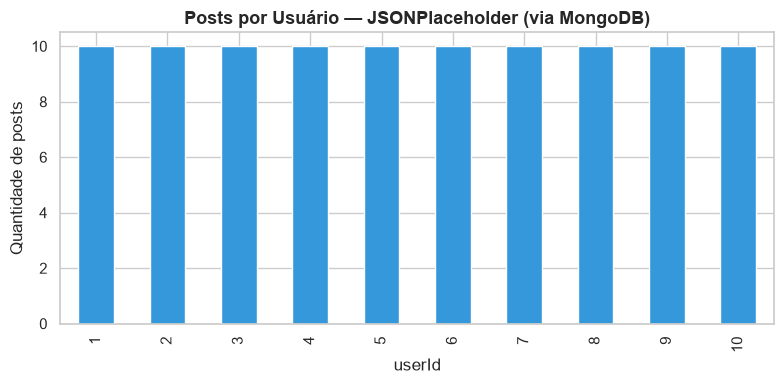

In [10]:
import requests
from pymongo import MongoClient

# ── Conexão (mesmos conceitos da Aula 07: API, REST, JSON, NoSQL) ─────────
cliente_mongo = MongoClient('mongodb://localhost:27017')
db = cliente_mongo['exercicio_aula07']
colecao_posts = db['posts_api']

# ── Passo 1: GET na API de teste ───────────────────────────────────────────
resposta = requests.get('https://jsonplaceholder.typicode.com/posts', timeout=10)
print(f'Status da requisição: {resposta.status_code} ({"OK" if resposta.ok else "ERRO"})')
posts_json = resposta.json()
print(f'Total de posts recebidos: {len(posts_json)}')

# ── Passo 2: gravar no MongoDB ──────────────────────────────────────────────
colecao_posts.delete_many({})  # limpa para permitir reexecutar do zero
colecao_posts.insert_many(posts_json)
print(f'Documentos na coleção: {colecao_posts.count_documents({})}')

# ── Passo 3: consultar e voltar para o Pandas ──────────────────────────────
docs = list(colecao_posts.find({}, {'_id': 0, 'userId': 1, 'title': 1}))
df_posts = pd.DataFrame(docs)

contagem_por_usuario = df_posts.groupby('userId').size().sort_values(ascending=False)
print('\nPosts publicados por usuário (userId):')
print(contagem_por_usuario)

fig, ax = plt.subplots(figsize=(8, 4))
contagem_por_usuario.sort_index().plot(kind='bar', ax=ax, color='#3498db')
ax.set_title('Posts por Usuário — JSONPlaceholder (via MongoDB)', fontsize=13, fontweight='bold')
ax.set_xlabel('userId')
ax.set_ylabel('Quantidade de posts')
plt.tight_layout()
plt.show()

---
## Pontuação sugerida

| Exercício | Pontos | Tema |
|-----------|--------|------|
| Ex. 1 | 1,5 | Pré-processamento: duplicatas, valores ausentes, codificação |
| Ex. 2 | 2,0 | Classificação: Árvore de Decisão + métricas de avaliação |
| Ex. 3 | 2,0 | Agrupamento: K-Means + Método do Cotovelo |
| Ex. 4 | 2,0 | Regras de Associação: suporte, confiança, lift |
| Ex. 5 | 2,5 | Coleta REST + MongoDB → Pandas |
| **Total** | **10,0** | |

---
**Prof. Mesc. Diego Ramos Inácio · Ciência de Dados · Univassouras · 2026**